# 02 · Prepare the Data, Shortlist & Compare Models
Checklist sections covered:
* **Prepare the data** — cleaning, feature engineering, scaling, all inside a leak-free scikit-learn `Pipeline`
* **Shortlist promising models** — quick-and-dirty models from many families with **5-fold CV (mean ± std)**
* **Analyse** the most significant variables and the **types of errors**, iterate on features, and
  **shortlist 3–5 models** that make *different* errors.

The test set (arrivals May–Aug 2017) is **not touched** in this notebook.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from src.evaluation import best_f1_threshold, evaluate_cv, make_cv, summarise, time_cv
from src.features import (FIG_DIR, MODEL_DIR, RANDOM_STATE, TARGET, FeatureEngineer,
                          SegmentRateBaseline, basic_clean, duplicate_groups, load_raw,
                          make_pipeline, temporal_split)

sns.set_theme(style="whitegrid")
FIG_DIR.mkdir(parents=True, exist_ok=True); MODEL_DIR.mkdir(parents=True, exist_ok=True)
set_config(display="diagram")


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Load, clean and split
* `basic_clean()` removes the data-entry errors found in the EDA (0-guest bookings, negative / absurd `adr`)
  and turns `Undefined` codes into missing values. These are fixed rules that learn nothing from the data,
  so applying them before the split cannot leak information.
* `temporal_split()`: **train** = arrivals before 1 May 2017, **test** = 1 May → 31 Aug 2017.

In [2]:
data = basic_clean(load_raw())
train, test = temporal_split(data)
X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
groups = duplicate_groups(X_train)
print(f"train {X_train.shape}, test {test.shape}; positive rate train={y_train.mean():.3f}")
print(f"{pd.Series(groups).duplicated().sum():,} training rows share a duplicate group")

train (97031, 32), test (22177, 33); positive rate train=0.363
30,624 training rows share a duplicate group


## 2. The preprocessing pipeline
All transformations are implemented in [`src/features.py`](../src/features.py) and chained in one `Pipeline`, so
that inside cross-validation **every learned step is fitted on the training folds only**:

| Step | What | Why |
|---|---|---|
| `FeatureEngineer` (stateless) | drop leaky columns (`reservation_status`, `reservation_status_date`, `assigned_room_type`), the **post-booking columns** (`total_of_special_requests`, `required_car_parking_spaces`, `booking_changes` — not known at booking time, see notebook 01 §6) and columns replaced by better versions; create 16 new features: `log_lead_time`, `total_nights`, `total_guests`, `has_kids`, `weekend_share`, `adr_per_guest`, `total_revenue`, arrival & booking month / weekday, `prev_cancel_ratio`, `has_history`, `has_agent`, `has_company` | Leakage removal + booking-time restriction + transformations suggested by the EDA (skew, aggregation, date decomposition, flags) |
| Numeric: `SimpleImputer(median)` → `StandardScaler` | scaling only for scale-sensitive models (linear, SVM, NB, MLP) | Trees are scale-invariant, so their pipeline skips scaling |
| Categorical: `SimpleImputer("missing")` → `OneHotEncoder(min_frequency=50)` (linear/NN) or `OrdinalEncoder(min_frequency=50)` (trees) | rare `country` / `agent` levels (< 50 rows) are grouped into one "infrequent" level; unseen levels at prediction time are handled | Avoids hundreds of sparse dummy columns and over-fitting to tiny agents/countries |

`min_frequency`, `use_country`, `booking_time` and feature engineering on/off are exposed as pipeline parameters so we can treat
**data-preparation choices as hyper-parameters** (Checklist: *"treat your data transformation choices as hyperparameters"*).

In [3]:
example = make_pipeline(LogisticRegression(max_iter=2000), kind="onehot")
example

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,use_country,True
,booking_time,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``f

In [4]:
fe = FeatureEngineer().fit_transform(X_train.head(1000))
prep = example.named_steps["prep"].fit(fe)
print(f"{X_train.shape[1]} raw columns → {fe.shape[1]} after feature engineering → "
      f"{prep.transform(fe).shape[1]} model inputs after one-hot encoding")

32 raw columns → 35 after feature engineering → 56 model inputs after one-hot encoding


## 3. Cross-validation design
We compare three ways of validating the same LightGBM pipeline:
* **plain `StratifiedKFold`** — random 5 folds;
* **`StratifiedGroupKFold`** — random 5 folds, but rows that are identical *as the model sees them* (same
  engineered features: ~28% of rows, mostly group bookings) share a group and always sit in the same fold;
* **forward-in-time (expanding window)** — train on everything before a date, validate on the next 4 months
  (validation periods May–Aug 2016, Sep–Dec 2016, Jan–Apr 2017), exactly how the model will be used.

For each scheme we also measure how many validation rows have a model-identical "twin" in the training part.

In [5]:
lgbm_quick = make_pipeline(LGBMClassifier(random_state=RANDOM_STATE, verbose=-1), kind="ordinal")
schemes = {
    "plain StratifiedKFold": list(StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X_train, y_train)),
    "StratifiedGroupKFold (model-visible twins grouped)": list(make_cv().split(X_train, y_train, groups)),
    "forward-in-time (3 expanding windows)": time_cv(train.arrival_date),
}
rows = {}
for name, folds in schemes.items():
    f, _ = evaluate_cv(lgbm_quick, X_train, y_train, groups, cv=folds, name=name)
    twin = np.mean([np.isin(groups[va], groups[tr]).mean() for tr, va in folds])
    rows[name] = {"ROC-AUC": f.roc_auc.mean(), "ROC-AUC std": f.roc_auc.std(), "PR-AUC": f.pr_auc.mean(),
                  "val rows with a twin in train": twin}
cv_schemes = pd.DataFrame(rows).T
cv_schemes.round(4)

,ROC-AUC,ROC-AUC std,PR-AUC,val rows with a twin in train
plain StratifiedKFold,0.9287,0.0010,0.8983,0.3713
StratifiedGroupKFold (model-visible twins grouped),0.9184,0.0040,0.8833,0.0000
forward-in-time (3 expanding windows),0.8275,0.0448,0.7846,0.0006


**Takeaways:**
* With plain folds **37% of validation rows have an exact model-identical twin** in the training part, and the
  score is inflated (ROC-AUC 0.929 vs 0.918). Grouping by the model-visible features removes every twin (0%).
* The grouping key must use **only the columns the model sees**: hashing all raw columns (including
  `reservation_status` or `booking_changes`, which the model never sees) would split model-identical rows into
  different groups and still leak (we measured ≈ 12% twins with that earlier key).
* **Forward-in-time validation is much more pessimistic — and the most realistic** (0.828 ± 0.045): the model is
  always scored on *future* bookings, as in deployment. Its large spread comes from the first window, where the
  model is trained on only ten months of data. We therefore use it for **tuning and model selection** in
  notebook 03. Here, for the broad comparison of nine model families, we keep the grouped 5-fold CV (more folds →
  a mean ± std per model); the *ranking* of model families is what matters at this stage.

## 4. Baselines
* **Dummy** — always predicts the prior (AUC 0.5 by construction).
* **Business rule** (`SegmentRateBaseline`) — what a revenue manager can do today with a pivot table: predict the
  historical cancellation rate of the booking's *hotel × market segment × deposit type* cell.

In [6]:
results, oof = [], {}
for name, model in {
    "Dummy (prior)": make_pipeline(DummyClassifier(strategy="prior"), kind="onehot"),
    "Business rule (segment rate)": SegmentRateBaseline(),
}.items():
    f, p = evaluate_cv(model, X_train, y_train, groups, name=name)
    results.append(f); oof[name] = p
summarise(pd.concat(results)).round(4)

,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,fit_s_per_fold
model,,,,,,,,,,,
Business rule (segment rate),0.7602,0.0059,0.6757,0.0067,0.5217,0.0089,0.9927,0.0038,0.3538,0.0085,0.0706
Dummy (prior),0.5000,0.0000,0.3628,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.7987


**Takeaway:** the simple rule is a meaningful baseline (ROC-AUC ≈ 0.76): it is **99% precise but catches only
~35% of cancellations** — essentially the *Non Refund* cells. Any ML model has to clearly beat this to be worth deploying.

## 5. Quick-and-dirty models from different families (default hyper-parameters)

In [7]:
candidates = {
    "Logistic Regression": (LogisticRegression(max_iter=2000), "onehot"),
    "Gaussian Naive Bayes": (GaussianNB(), "onehot"),
    "Linear SVM": (CalibratedClassifierCV(LinearSVC(C=0.1), cv=3), "onehot"),
    "Decision Tree": (DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE), "ordinal"),
    "Random Forest": (RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE), "ordinal"),
    "HistGradientBoosting": (HistGradientBoostingClassifier(random_state=RANDOM_STATE), "ordinal"),
    "XGBoost": (XGBClassifier(n_jobs=-1, random_state=RANDOM_STATE, eval_metric="logloss"), "ordinal"),
    "LightGBM": (LGBMClassifier(random_state=RANDOM_STATE, verbose=-1), "ordinal"),
    "MLP (neural net)": (MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                                       random_state=RANDOM_STATE, max_iter=200), "onehot"),
}
for name, (model, kind) in candidates.items():
    f, p = evaluate_cv(make_pipeline(model, kind=kind), X_train, y_train, groups, name=name)
    results.append(f); oof[name] = p
    print(f"{name:28s} ROC-AUC {f.roc_auc.mean():.4f} ± {f.roc_auc.std():.4f}   ({f.fit_seconds.mean():.0f}s/fold)")

all_folds = pd.concat(results)
summary = summarise(all_folds)
summary.round(4)

Logistic Regression          ROC-AUC 0.8890 ± 0.0046   (3s/fold)


Gaussian Naive Bayes         ROC-AUC 0.7810 ± 0.0064   (1s/fold)


Linear SVM                   ROC-AUC 0.8637 ± 0.0031   (4s/fold)


Decision Tree                ROC-AUC 0.8935 ± 0.0064   (1s/fold)


Random Forest                ROC-AUC 0.9168 ± 0.0033   (18s/fold)


HistGradientBoosting         ROC-AUC 0.9178 ± 0.0040   (56s/fold)


XGBoost                      ROC-AUC 0.9200 ± 0.0028   (13s/fold)


LightGBM                     ROC-AUC 0.9184 ± 0.0040   (27s/fold)


MLP (neural net)             ROC-AUC 0.9139 ± 0.0034   (13s/fold)


,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,fit_s_per_fold
model,,,,,,,,,,,
XGBoost,0.9200,0.0028,0.8850,0.0028,0.7527,0.0041,0.8174,0.0044,0.6976,0.0070,13.1541
LightGBM,0.9184,0.0040,0.8833,0.0052,0.7474,0.0091,0.8298,0.0068,0.6798,0.0108,27.2639
HistGradientBoosting,0.9178,0.0040,0.8823,0.0050,0.7465,0.0043,0.8297,0.0057,0.6784,0.0049,56.3333
Random Forest,0.9168,0.0033,0.8830,0.0031,0.7517,0.0044,0.8358,0.0089,0.6830,0.0068,18.2458
MLP (neural net),0.9139,0.0034,0.8796,0.0044,0.7570,0.0047,0.8009,0.0202,0.7180,0.0109,12.7988
Decision Tree,0.8935,0.0064,0.8345,0.0069,0.6849,0.0080,0.8239,0.0376,0.5873,0.0225,1.2322
Logistic Regression,0.8890,0.0046,0.8481,0.0046,0.6995,0.0062,0.8131,0.0126,0.6139,0.0087,3.3265
Linear SVM,0.8637,0.0031,0.8292,0.0025,0.7136,0.0039,0.7360,0.0109,0.6928,0.0157,4.0230
Gaussian Naive Bayes,0.7810,0.0064,0.6816,0.0177,0.6114,0.0215,0.6964,0.0614,0.5552,0.0786,0.9894


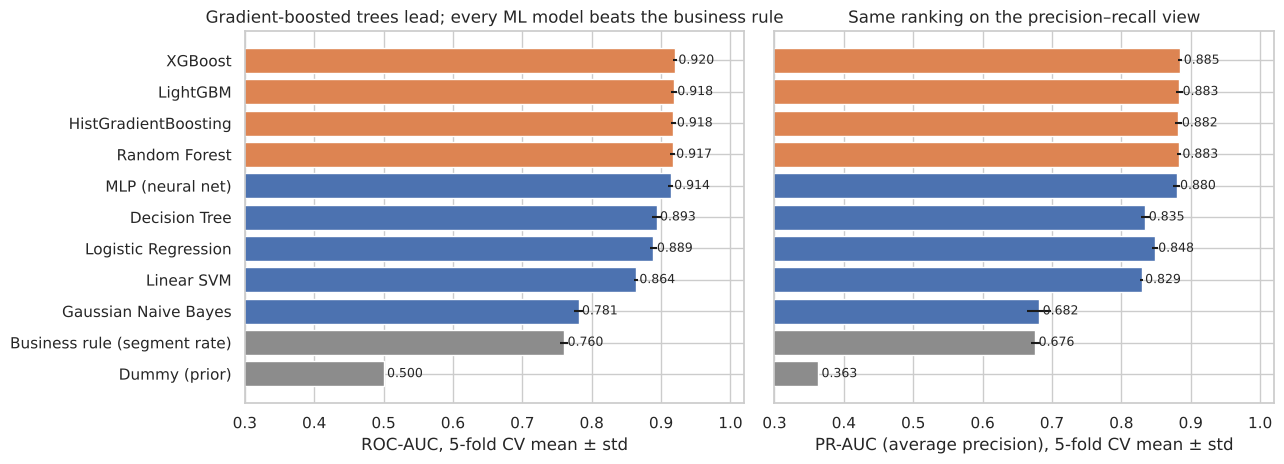

In [8]:
order = summary.index[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, metric, label in zip(axes, ["roc_auc", "pr_auc"], ["ROC-AUC", "PR-AUC (average precision)"]):
    ax.barh(order, summary.loc[order, f"{metric}_mean"], xerr=summary.loc[order, f"{metric}_std"],
            color=["#DD8452" if ("Boost" in n or "GBM" in n or "Forest" in n) else
                   "#8C8C8C" if n.startswith(("Dummy", "Business")) else "#4C72B0" for n in order])
    for i, v in enumerate(summary.loc[order, f"{metric}_mean"]):
        ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
    ax.set_xlim(0.3, 1.02); ax.set_xlabel(f"{label}, 5-fold CV mean ± std")
axes[0].set_title("Gradient-boosted trees lead; every ML model beats the business rule")
axes[1].set_title("Same ranking on the precision–recall view")
fig.tight_layout(); save(fig, "model_comparison_cv"); plt.show()

**Takeaways:**
* **Tree ensembles (XGBoost, LightGBM, HistGB, Random Forest) are best** (ROC-AUC ≈ 0.917–0.920), as the EDA
  predicted (non-linear effects such as lead time, and interactions such as *Non Refund × Groups × PRT*).
* The **MLP** is close behind (0.914); **Logistic Regression** (0.889) and a single **Decision Tree** (0.894) are
  good interpretable references. The calibrated linear SVM is lower (0.864).
* **Naive Bayes** is clearly worst (0.781): its independence assumption is violated (many correlated / one-hot inputs).
* Standard deviations across folds are small (≤ 0.006), so differences of > 0.01 AUC are meaningful.
* Every model beats the business rule (0.760); the boosted trees add **+0.16 AUC** and roughly **double the
  recall** (≈ 0.70 vs 0.35) while keeping precision ≈ 0.82.

## 6. Most significant variables
### 6a. Permutation importance (model-agnostic, on *original* attributes)
We hold out one CV fold, fit LightGBM and Logistic Regression on the rest, and measure how much the
validation ROC-AUC drops when each **raw** column is shuffled (the whole pipeline is re-run, so engineered features
derived from a column are disrupted too).

In [9]:
tr_idx, va_idx = next(make_cv().split(X_train, y_train, groups))
X_tr, X_va, y_tr, y_va = X_train.iloc[tr_idx], X_train.iloc[va_idx], y_train.iloc[tr_idx], y_train.iloc[va_idx]
cols = [c for c in X_train.columns if c not in ("reservation_status", "reservation_status_date",
                                                  "assigned_room_type", "arrival_date_year",
                                                  "required_car_parking_spaces", "total_of_special_requests",
                                                  "booking_changes",
                                                  "arrival_date_week_number", "arrival_date_day_of_month")]
X_va_s = X_va.sample(8000, random_state=0); y_va_s = y_va.loc[X_va_s.index]
imp = {}
for name, kind, model in [("LightGBM", "ordinal", LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)),
                          ("Logistic Regression", "onehot", LogisticRegression(max_iter=2000))]:
    pipe = make_pipeline(model, kind=kind).fit(X_tr, y_tr)
    r = permutation_importance(pipe, X_va_s, y_va_s,
                               scoring="roc_auc", n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
    imp[name] = pd.Series(r.importances_mean, index=X_va.columns)
imp = pd.DataFrame(imp).loc[cols].sort_values("LightGBM", ascending=False)
imp.head(15).round(4)

,LightGBM,Logistic Regression
country,0.1036,0.0663
deposit_type,0.0893,0.0719
market_segment,0.0658,0.0102
agent,0.0634,0.0593
lead_time,0.0515,0.0460
previous_cancellations,0.0414,0.0469
customer_type,0.0270,0.0208
adr,0.0067,0.0005
arrival_date,0.0065,0.0008
stays_in_week_nights,0.0062,0.0026


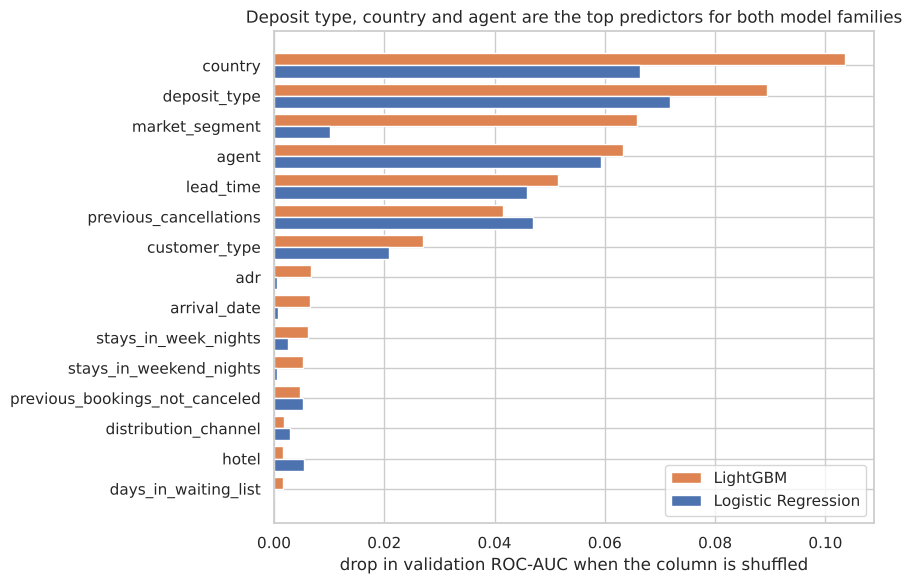

In [10]:
top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
y_pos = np.arange(len(top))
ax.barh(y_pos + 0.2, top["LightGBM"], height=0.4, label="LightGBM", color="#DD8452")
ax.barh(y_pos - 0.2, top["Logistic Regression"], height=0.4, label="Logistic Regression", color="#4C72B0")
ax.set_yticks(y_pos); ax.set_yticklabels(top.index)
ax.set_xlabel("drop in validation ROC-AUC when the column is shuffled")
ax.set_title("Deposit type, country and agent are the top predictors for both model families")
ax.legend(); fig.tight_layout(); save(fig, "permutation_importance"); plt.show()

### 6b. Logistic-regression coefficients (direction of the effect)

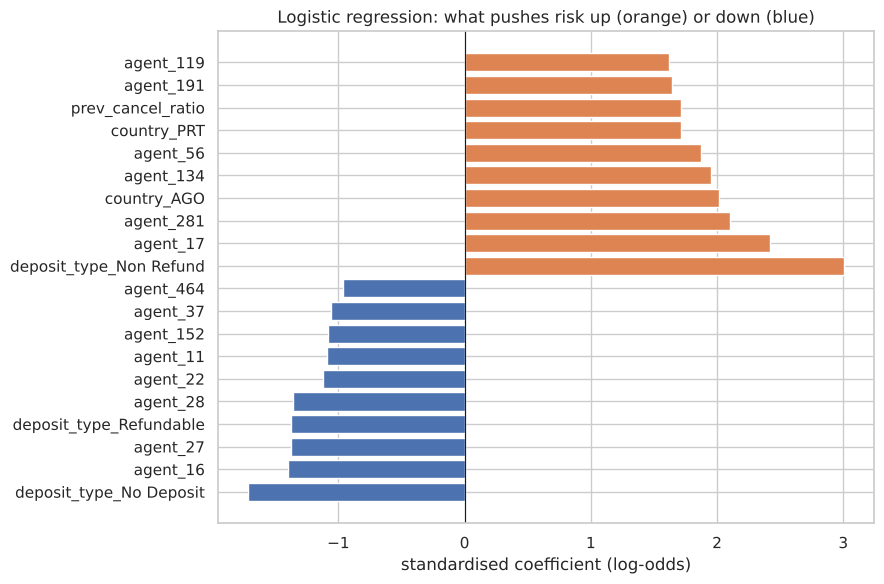

In [11]:
lr_pipe = make_pipeline(LogisticRegression(max_iter=2000), kind="onehot").fit(X_tr, y_tr)
coef = pd.Series(lr_pipe.named_steps["model"].coef_[0],
                 index=lr_pipe.named_steps["prep"].get_feature_names_out())
coef_top = pd.concat([coef.nsmallest(10), coef.nlargest(10)])
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(coef_top.index, coef_top.values, color=["#4C72B0" if v < 0 else "#DD8452" for v in coef_top.values])
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("standardised coefficient (log-odds)")
ax.set_title("Logistic regression: what pushes risk up (orange) or down (blue)")
fig.tight_layout(); save(fig, "logreg_coefficients"); plt.show()

**Takeaways:**
* Both model families agree on the top drivers: **country, deposit type, agent, lead time and previous
  cancellations** — consistent with the EDA. The tree model also leans on `market_segment`, which the linear model
  mostly gets through `agent` and `deposit_type`.
* The coefficients give the **direction**: a non-refundable deposit, a history of cancellations, Portuguese (and
  Angolan) bookings and a handful of specific travel agents push risk up; no-deposit / refundable bookings and other
  agents push it down. **Which agent made the booking** matters a lot — something a revenue manager can act on.
* `country` is the #1 variable for the tree model — exactly the column we flagged as possibly leaky, so we must
  test how much we depend on it (§8).

## 7. What kinds of errors do the models make?
We use the **out-of-fold** predictions of LightGBM (every training row predicted by a model that did not see it).

F1-optimal threshold on OOF predictions: 0.41 (F1 = 0.772)


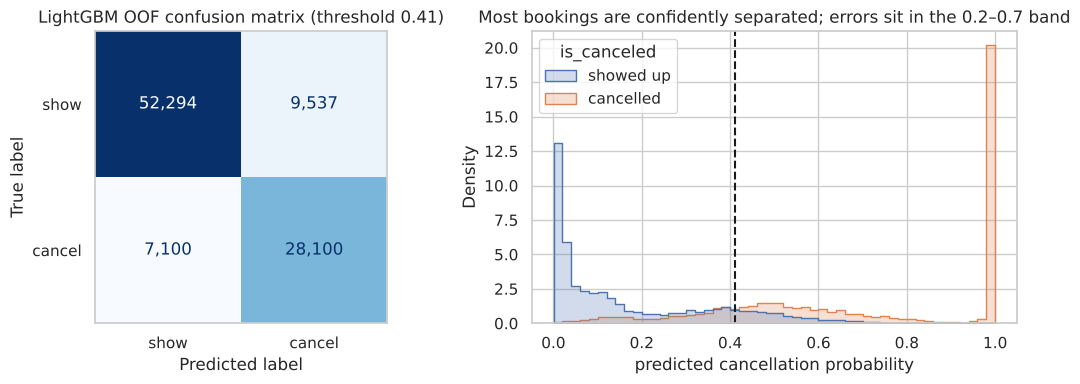

In [12]:
p_lgbm = oof["LightGBM"]
thr, f1_best = best_f1_threshold(y_train, p_lgbm)
pred = (p_lgbm >= thr).astype(int)
print(f"F1-optimal threshold on OOF predictions: {thr:.2f} (F1 = {f1_best:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_train, pred), display_labels=["show", "cancel"]).plot(
    ax=axes[0], colorbar=False, values_format=",", cmap="Blues"); axes[0].grid(False)
axes[0].set_title(f"LightGBM OOF confusion matrix (threshold {thr:.2f})")
sns.histplot(x=p_lgbm, hue=y_train.map({0: "showed up", 1: "cancelled"}), bins=50, ax=axes[1],
             element="step", stat="density", common_norm=False)
axes[1].axvline(thr, color="k", ls="--"); axes[1].set_xlabel("predicted cancellation probability")
axes[1].set_title("Most bookings are confidently separated; errors sit in the 0.2–0.7 band")
fig.tight_layout(); save(fig, "oof_confusion"); plt.show()

In [13]:
err = train.assign(p=p_lgbm, pred=pred,
                   error=np.select([(pred == 1) & (y_train == 0), (pred == 0) & (y_train == 1)],
                                   ["false alarm", "missed cancel"], "correct"))
err["lead_bucket"] = pd.cut(err.lead_time, [-1, 7, 30, 90, 180, 365, 800],
                            labels=["≤7", "8-30", "31-90", "91-180", "181-365", "365+"])


def error_table(col):
    t = pd.crosstab(err[col], err.error, normalize="index").mul(100).round(1)
    t["n"] = err[col].value_counts()
    return t.sort_values("missed cancel", ascending=False)


display(error_table("market_segment"))
display(error_table("lead_bucket"))
display(error_table("deposit_type"))

error,correct,false alarm,missed cancel,n
market_segment,,,,
Aviation,81.1,4.3,14.6,164
Complementary,88.2,0.5,11.3,626
Direct,87.0,1.7,11.3,10113
Online TA,73.4,17.5,9.2,43334
Corporate,90.7,1.2,8.0,4689
Offline TA/TO,90.3,5.6,4.2,20630
Groups,92.9,3.4,3.7,17473


error,correct,false alarm,missed cancel,n
lead_bucket,,,,
8-30,78.5,9.2,12.3,16195
≤7,91.5,0.3,8.2,17408
31-90,77.2,14.7,8.1,25812
91-180,78.4,15.1,6.4,19467
181-365,90.3,7.6,2.1,16060
365+,98.6,1.2,0.2,2089


error,correct,false alarm,missed cancel,n
deposit_type,,,,
No Deposit,80.3,11.3,8.4,84331
Refundable,88.7,5.0,6.4,141
Non Refund,99.8,0.2,0.0,12559


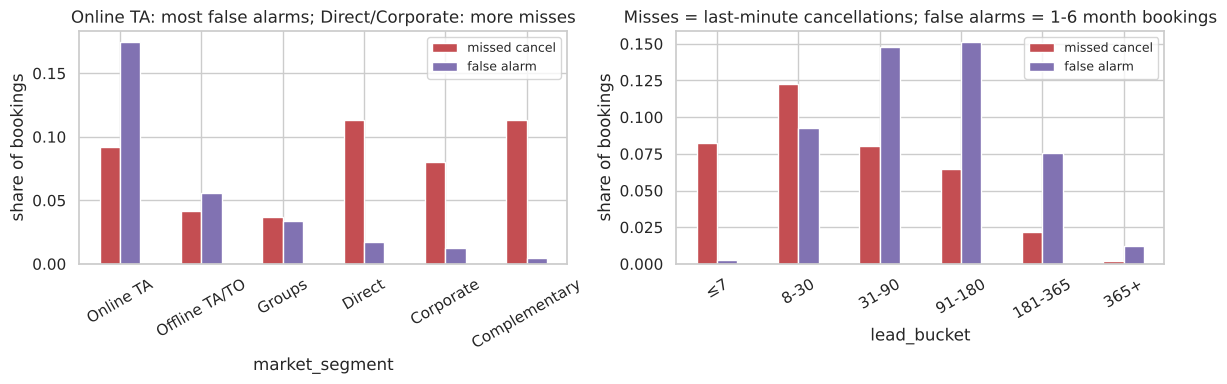

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["market_segment", "lead_bucket"]):
    t = pd.crosstab(err[col], err.error, normalize="index")[["missed cancel", "false alarm"]]
    keep = err[col].value_counts().loc[lambda s: s >= 300].index
    t = t.loc[[i for i in t.index if i in keep]]          # keeps the natural order of lead-time buckets
    if col == "market_segment":
        t = t.sort_values("false alarm", ascending=False)
    t.plot.bar(ax=ax, color=["#C44E52", "#8172B2"], rot=30)
    ax.legend(loc="upper right", fontsize=9)
    ax.set_ylabel("share of bookings"); ax.set_xlabel(col)
axes[0].set_title("Online TA: most false alarms; Direct/Corporate: more misses")
axes[1].set_title("Misses = last-minute cancellations; false alarms = 1-6 month bookings")
fig.tight_layout(); save(fig, "error_analysis"); plt.show()

**Error analysis — takeaways** (threshold 0.41 → ≈ 7,100 missed cancellations and ≈ 9,500 false alarms out of 97k):
* **Non-Refund / Groups are essentially solved** (99.8% correct). The model's difficulty is the ordinary
  *No Deposit, transient* booking.
* **False alarms** concentrate in **Online TA** bookings (17.5% of them) made **1–6 months ahead** (≈ 15%): they
  have the "risky" profile (online, no deposit, mid lead time) but the guest did show up. Without the post-booking
  columns the model cannot see that these guests later added requests or parking — the signal that used to rescue
  them (compare the upper-bound row F in §8).
* **Missed cancellations** are mostly **short-lead-time bookings** (≤ 30 days, 8–12% missed) and Direct /
  Corporate / Aviation bookings — profiles that normally show up, so the model has no warning signal.
* **What data would a human use to avoid these errors?** A revenue manager would look at **whether the guest
  gave a card guarantee / paid**, **price drops since booking** (online guests cancel to rebook cheaper),
  **e-mail engagement** (opened the confirmation, checked in online?), the **free-cancellation deadline**, and
  **loyalty history across hotels**. None of these are in the dataset → listed as extra data to collect.

## 8. Iterate: feature selection & engineering (quick ablations with LightGBM)
Each variant below changes only one data-preparation choice. Same CV, same model.

In [15]:
ablations = {
    "A. full pipeline (engineered features, country, min_freq=50)": dict(),
    "B. no engineered features (original columns only)": dict(engineered=False),
    "C. without country": dict(use_country=False),
    "D. rare-level threshold min_freq=10": dict(min_frequency=10),
    "E. rare-level threshold min_freq=200": dict(min_frequency=200),
    "F. + post-booking columns (parking, special requests, changes) — upper bound": dict(booking_time=False),
}
abl = []
for name, kw in ablations.items():
    f, _ = evaluate_cv(make_pipeline(LGBMClassifier(random_state=RANDOM_STATE, verbose=-1), kind="ordinal", **kw),
                       X_train, y_train, groups, name=name)
    abl.append(f)
abl = summarise(pd.concat(abl))[["roc_auc_mean", "roc_auc_std", "pr_auc_mean", "f1_mean"]]
abl["Δ ROC-AUC vs A"] = abl["roc_auc_mean"] - abl.loc[list(ablations)[0], "roc_auc_mean"]
abl.round(4)

,roc_auc_mean,roc_auc_std,pr_auc_mean,f1_mean,Δ ROC-AUC vs A
model,,,,,
"F. + post-booking columns (parking, special requests, changes) — upper bound",0.9442,0.0030,0.9172,0.8125,0.0258
B. no engineered features (original columns only),0.9189,0.0040,0.8837,0.7485,0.0005
D. rare-level threshold min_freq=10,0.9186,0.0035,0.8832,0.7470,0.0002
"A. full pipeline (engineered features, country, min_freq=50)",0.9184,0.0040,0.8833,0.7474,0.0000
E. rare-level threshold min_freq=200,0.9179,0.0042,0.8824,0.7480,-0.0005
C. without country,0.8632,0.0031,0.8326,0.6739,-0.0552


Trees can learn most transformations on their own, so feature engineering should matter more for a **linear**
model. Same ablation (A vs B) with Logistic Regression:

In [16]:
lr_abl = []
for name, kw in {"LogReg A. engineered features": dict(), "LogReg B. original columns only": dict(engineered=False)}.items():
    f, _ = evaluate_cv(make_pipeline(LogisticRegression(max_iter=2000), kind="onehot", **kw),
                       X_train, y_train, groups, name=name)
    lr_abl.append(f)
summarise(pd.concat(lr_abl))[["roc_auc_mean", "roc_auc_std", "pr_auc_mean", "f1_mean"]].round(4)

,roc_auc_mean,roc_auc_std,pr_auc_mean,f1_mean
model,,,,
LogReg A. engineered features,0.8890,0.0046,0.8481,0.6995
LogReg B. original columns only,0.8777,0.0058,0.8309,0.6778


**Takeaways:**
* **Feature engineering makes no difference for the boosted trees** (A vs B: within ±0.0005 AUC, inside the fold
  noise) — they already capture non-linear effects such as the lead-time curve. It does help the **linear model**
  (LogReg: 0.878 → 0.889 AUC, F1 +0.02), where `log_lead_time` and the flags encode non-linearity explicitly. We keep
  the engineered features: they help the linear/NN models and make the final model easier to explain.
* **`country` is worth ≈ 0.055 AUC** (C vs A) — by far the largest effect. It is also the column the dataset paper
  warns may be corrected only at check-in. We keep it in the main model (it is recorded at booking for most
  channels) but carry the **"without country" variant to the final test** as a conservative lower bound, and
  list it as the #1 assumption to validate with the hotel's IT team.
* **Post-booking columns would add ≈ 0.026 AUC** (F vs A: 0.918 → 0.944). That is the price of predicting at
  booking time instead of just before arrival. We accept it: by the time these fields are filled in, most
  cancellations have already happened (notebook 01 §6). Row F is carried to the final test as an *upper bound*.
* The rare-level threshold barely matters (D, E); it is searched again as a hyper-parameter in notebook 03.

## 9. Shortlist
We prefer models that are both accurate **and make different errors** (useful for an ensemble). Correlation of
the out-of-fold residuals:

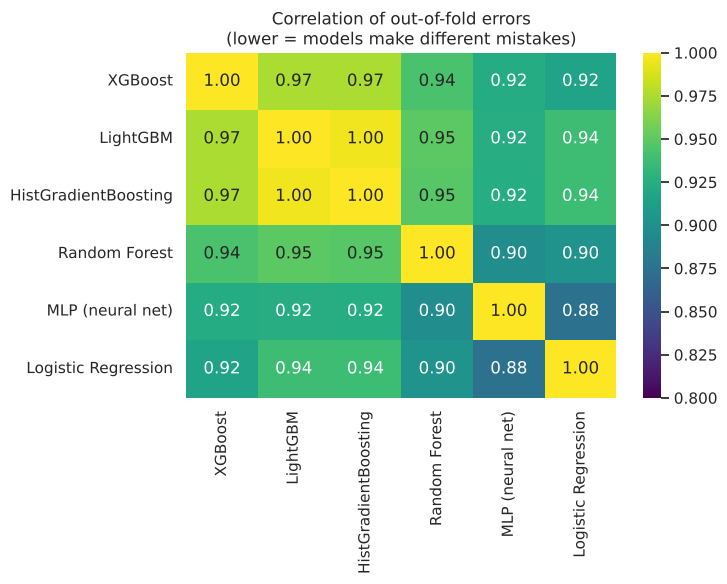

In [17]:
names = ["XGBoost", "LightGBM", "HistGradientBoosting", "Random Forest", "MLP (neural net)", "Logistic Regression"]
resid = pd.DataFrame({n: y_train.values - oof[n] for n in names})
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(resid.corr(), annot=True, fmt=".2f", cmap="viridis", vmin=0.8, vmax=1, ax=ax)
ax.set_title("Correlation of out-of-fold errors\n(lower = models make different mistakes)")
fig.tight_layout(); save(fig, "error_correlation"); plt.show()

**Shortlisted for fine-tuning (4 models):**

| Model | Why |
|---|---|
| **XGBoost** | Best CV ROC-AUC and PR-AUC; fast; handles interactions natively. |
| **LightGBM** | Equal accuracy, fastest to train → cheapest to tune; leaf-wise growth differs from XGBoost. |
| **Random Forest** | Bagging instead of boosting → errors less correlated with the boosters (≈ 0.94–0.95 vs 0.975 between XGBoost and LightGBM). |
| **MLP** | Different family (neural net on one-hot, scaled inputs); **least correlated errors** with the trees (≈ 0.90–0.93) → best ensemble partner. |

*Not shortlisted:* HistGradientBoosting (near-duplicate of LightGBM, error correlation 0.995), Logistic Regression and
Linear SVM (0.03–0.06 AUC behind — Logistic Regression is kept as the interpretable reference), Decision Tree and Naive Bayes (clearly weaker).

In [18]:
summary.to_csv(MODEL_DIR / "cv_results_shortlist_stage.csv")
pd.DataFrame(oof).assign(y=y_train.values).to_csv(MODEL_DIR / "oof_predictions_stage02.csv", index=False)
print("saved CV summary and OOF predictions")

saved CV summary and OOF predictions
